# AI Fundamentals Coding Challenge

**Nama:** Putu Sintha Atisya Armayanti
**Tanggal:** 13 Oktober 2026
**Link Dataset yang digunakan:** https://www.kaggle.com/datasets/tonylm00/business-companies-dataset

---
## Daftar Isi
1. [Challenge 1 - Data Exploration](#challenge-1)
2. [Challenge 2 - Machine Learning](#challenge-2)
3. [Challenge 3 - Prediction](#challenge-3)
4. [Challenge 4 - Integrasi Gemini API](#challenge-4)
5. [Challenge 5 - Responsible AI Reflection](#challenge-5)

---


Catatan terkait Dataset:
1. Silahkan gunakan dataset yang sesuai dengan ide mini demo day kelompok kamu atau dapat dicari di open source platform lainnya seperti:
  a. https://www.kaggle.com/datasets
  b. https://www.bps.go.id/
  c. https://data.worldbank.org
  d. https://data.cityofchicago.org/
  e. https://djpk.kemenkeu.go.id/portal/data/apbd
  f. https://archive.ics.uci.edu/datasets
  

## Setup Awal
Jalankan cell di bawah ini terlebih dahulu sebelum mengerjakan challenge apa pun.

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Import library dasar
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from dotenv import load_dotenv

from sklearn.model_selection import train_test_split

%matplotlib inline
RANDOM_STATE = 1082026  # gunakan nilai ini di semua fungsi yang membutuhkan random_state

print('Setup berhasil. Library siap digunakan.')

Setup berhasil. Library siap digunakan.


---
<a id='challenge-1'></a>
## Challenge 1 - Data Exploration (Pandas)

**Tujuan:** Memahami struktur dataset, mendeteksi missing values, dan menampilkan insight awal.

### Instruksi
- Muat dataset ke dalam DataFrame
- Tampilkan 5 baris pertama, info(), dan describe()
- Cek missing values dan duplikasi data
- Buat minimal 2 visualisasi dari pilihan berikut: distribusi fitur, histogram, scatter plot, correlation heatmap, atau box plot
- Tuliskan insight dalam sel markdown berdasarkan pertanyaan yang diberikan

In [4]:
# Soal 1.1: Muat dataset
# Masukkan path dataset yang sesuai (contoh: '../data/nama_dataset.csv')
df = pd.read_csv('/content/drive/MyDrive/Perempuan Inovasi 2026/AI Coding/Challenge/companies.csv', sep=';')
print(f'Dataset shape: {df.shape}')
df.head()

Dataset shape: (7610, 85)


,domain,name,ticker,involvement.Alcoholic Beverages,involvement.Adult Entertainment,involvement.Gambling,involvement.Tobacco Products,involvement.Animal Testing,involvement.Fur and Specialty Leather,involvement.Controversial Weapons,...,Controversies.Impact on Local Communities,Controversies.Biodiversity & Land Use,Controversies.Other,Controversies.Marketing & Advertising,Controversies.Civil Liberties,Controversies.Operational Waste (Non-Hazardous),Controversies.Supply Chain Management,Controversies.Water Stress,Controversies.Child Labor,Controversies.Controversial Investments
0,f5.com,F5 Networks,FFIV,No,No,No,No,No,No,No,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,dell.com,Dell,DELL,No,No,No,No,No,No,No,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,att.com,AT&T,T,No,No,No,No,No,No,No,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,verizon.com,Verizon,VZ,No,No,No,No,No,No,No,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,hp.com,Hewlett Packard,HPQ,No,No,No,No,Yes,No,No,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Soal 1.2: Informasi umum dataset
print('=== Dataset Info ===')
df.info()

print('\n=== Dataset Describe ===')
print(df.describe())

print('\n=== Missing Values ===')
print(df.isnull().sum())

print('\n=== Duplicated Rows ===')
print(f'Total: {df.duplicated().sum()}')

=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7610 entries, 0 to 7609
Data columns (total 85 columns):
 #   Column                                                             Non-Null Count  Dtype  
---  ------                                                             --------------  -----  
 0   domain                                                             7610 non-null   object 
 1   name                                                               7610 non-null   object 
 2   ticker                                                             7489 non-null   object 
 3   involvement.Alcoholic Beverages                                    52 non-null     object 
 4   involvement.Adult Entertainment                                    52 non-null     object 
 5   involvement.Gambling                                               52 non-null     object 
 6   involvement.Tobacco Products                                       52 non-null     object 
 7   inv

In [ ]:
# Soal 1.3: Visualisasi data (minimal 2 grafik)
#
# GUIDE: Pilih 2-3 jenis visualisasi dari berikut:
# 1. Distribution/Histogram
# 2. Scatter plot (relationship antar features)
# 3. Correlation heatmap
# 4. Box plot (per kategori jika ada)
# 5. Pie chart (untuk categorical data)
#
# Contoh:


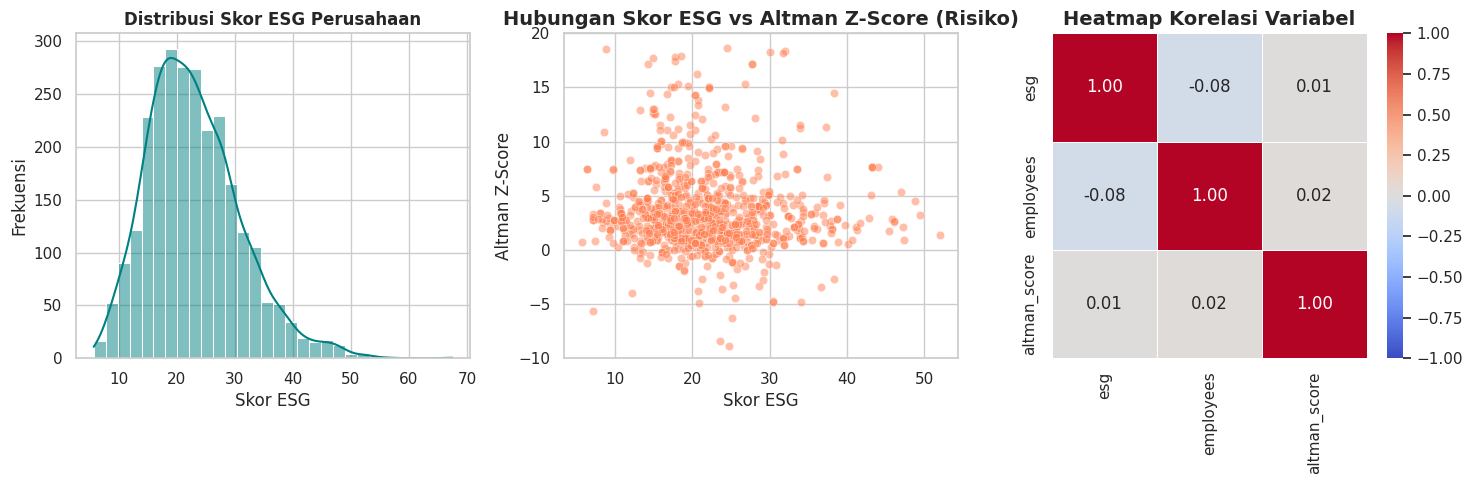

In [16]:
# Soal 1.3: Visualisasi data (minimal 2 grafik)

# Set style agar grafik terlihat lebih rapi
sns.set_theme(style="whitegrid")

# Membuat kanvas (fig) dengan 1 baris dan 2 kolom
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1. VISUALISASI DISTRIBUSI (HISTOGRAM)
# Menampilkan distribusi skor ESG
sns.histplot(df['esg'].dropna(), bins=30, kde=True, color='teal', ax=axes[0])
axes[0].set_title('Distribusi Skor ESG Perusahaan', fontweight='bold')
axes[0].set_xlabel('Skor ESG')
axes[0].set_ylabel('Frekuensi')

# 2. VISUALISASI HUBUNGAN (SCATTER PLOT)
sns.scatterplot(x='esg', y='altman_score', data=df, color='coral', alpha=0.5, ax=axes[1])
axes[1].set_title('Hubungan Skor ESG vs Altman Z-Score (Risiko)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Skor ESG')
axes[1].set_ylabel('Altman Z-Score')
axes[1].set_ylim(-10, 20) # Membatasi sumbu Y sesuai gambar

# 3. VISUALISASI KORELASI (HEATMAP)
# Menghitung korelasi khusus untuk kolom numerik yang relevan
korelasi = df[['esg', 'employees', 'altman_score']].corr()
# Membuat heatmap dengan anotasi angka korelasi
sns.heatmap(korelasi, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title('Heatmap Korelasi Variabel', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()


**Insight Challenge 1:**

Analisis berdasarkan pertanyaan berikut (min. 4-6 kalimat):

1. **Karakteristik Data**: Berapa jumlah rows/columns? Apa tipe data dari setiap column?
2. **Data Quality**: Apakah ada missing values atau duplicate rows? Jika ada, berapa banyak?
3. **Distribusi Fitur**: Bagaimana distribusi dari fitur-fitur utama? Apakah ada outliers?
4. **Korelasi**: Apakah ada korelasi menarik antara fitur? Fitur mana yang paling berkaitan?

Jawaban:

**1. Karakteristik Data**

**Dimensi Dataset**: Dataset companies.csv memuat informasi yang cukup besar, mencakup 7.610 perusahaan. Setiap perusahaan digambarkan melalui 85 kolom atribut yang berbeda.

**Tipe Data**: Dataset ini terdiri dari campuran dua jenis data utama:

Data Kualitatif (Teks/Kategorikal): Meliputi nama domain, nama perusahaan, kode saham (ticker), sektor, industri, status keterlibatan dengan senjata kontroversial, tembakau, minuman beralkohol, perjudian, evaluasi kontroversi (lingkungan, sosial, tata kelola), dan status kesesuaian target dekarbonisasi.

Data Kuantitatif (Numerik): Terdiri dari data rasio dan metrik, seperti skor Altman (untuk memprediksi risiko kebangkrutan), skor Piotroski (untuk menilai kekuatan finansial), jumlah karyawan, persentase target emisi komprehensif, dan skor lingkungan, sosial, serta tata kelola (ESG) secara umum.

**Format Khusus**: Dataset ini menggunakan tanda titik koma (;) sebagai pemisah kolom (delimiter), berbeda dengan file CSV konvensional yang umumnya menggunakan tanda koma (,).

**2. Kualitas Data (Data Quality)**

**Duplikasi Data**: Berdasarkan analisis, dataset ini sangat bersih dalam hal redudansi data. Tidak ditemukan satupun baris yang terduplikasi secara identik.

**Kelengkapan Data (Missing Values)**: Meskipun tidak ada baris yang duplikat, dataset ini memiliki tantangan dalam hal kelengkapan data. Terdapat banyak nilai kosong (missing values/Null) yang tersebar di berbagai kolom. Beberapa kolom yang paling banyak memiliki nilai kosong meliputi:

- Kolom-kolom yang berkaitan dengan tujuan spesifik SDGs (seperti indikator kemiskinan, kelaparan, dan perdamaian) tidak tersedia untuk banyak perusahaan.
- Target dan pencapaian terkait dekarbonisasi serta emisi perusahaan juga banyak yang tidak terisi.
- Detail spesifik mengenai keterlibatan dalam praktik kontroversial.

Hal ini mengindikasikan bahwa proses imputasi (pengisian nilai kosong) atau penghapusan kolom perlu dilakukan secara hati-hati sebelum menggunakan data ini untuk pemodelan Machine Learning. Namun, kolom-kolom inti yang akan dianalisis, seperti skor esg dan altman_score, mayoritas terisi dengan baik.

**3. Distribusi Fitur**

**Pola Skor ESG (Histogram)**: Mayoritas perusahaan di dalam dataset ini mendapatkan skor ESG pada rentang nilai menengah ke rendah. Secara spesifik, sebaran nilai ESG terkonsentrasi kuat di rentang 15 hingga 25.

**Bentuk Distribusi**: Distribusi skor ESG ini membentuk kurva yang condong ke kanan (right-skewed). Puncak frekuensi (mode) berada di kisaran skor 19. Hanya sebagian kecil perusahaan yang memiliki performa ESG sangat baik dengan skor di atas 40.

**Pencilan (Outliers)**: Terdapat beberapa perusahaan yang memiliki Altman Z-Score ekstrem (sangat tinggi atau sangat negatif). Saat melakukan visualisasi, batas pandang sumbu Y sebaiknya dibatasi (misalnya antara -10 hingga 20) agar grafik tidak rusak dan pola umum tetap terbaca dengan jelas.

**4. Korelasi**

Hubungan ESG dengan Stabilitas Finansial (Scatter Plot & Heatmap):

Analisis scatter plot antara skor ESG dan Altman Z-Score menunjukkan sebaran titik yang sangat acak (tersebar luas). Temuan visual ini divalidasi secara matematis melalui Heatmap Korelasi, di mana korelasi linier antara skor ESG dan Altman Z-Score terbukti sangat lemah, yaitu hanya sebesar 0.01. Selain itu, heatmap juga menunjukkan korelasi yang hampir tidak ada antara jumlah karyawan dengan Altman Z-Score (0.02), serta korelasi negatif yang sangat kecil antara skor ESG dan jumlah karyawan (-0.08).

**Temuan Utama**: Tidak ditemukan korelasi linier yang kuat atau jelas antara tingginya skor ESG suatu perusahaan dengan kestabilan finansial (risiko kebangkrutan) yang tercermin dari Altman Z-Score.

**Implikasi**:

Sebagian besar perusahaan berkumpul di rentang Altman Z-Score yang sehat (antara -5 hingga 10) terlepas dari tinggi rendahnya skor ESG yang dimiliki. Ini berarti tingginya skor ESG tidak secara otomatis menjamin sebuah perusahaan kebal dari risiko kebangkrutan.

Kondisi ini membuka peluang bagi pemodelan regresi atau klasifikasi yang lebih canggih di tahap Machine Learning selanjutnya. Tujuannya adalah untuk mendeteksi pola non-linier atau interaksi kompleks antara variabel ESG dan Altman Z-Score yang tidak dapat terlihat dari analisis korelasi linier sederhana.

---
<a id='challenge-2'></a>
## Challenge 2 - Machine Learning (Scikit-learn)

**Tujuan:** Melatih dan mengevaluasi model Machine Learning menggunakan Scikit-learn, kemudian membandingkan beberapa pendekatan untuk menentukan model yang paling sesuai dengan dataset dan tujuan prediksi Anda.

### Instruksi
- Pisahkan fitur (X) dan target (y) dari dataset
- **PENTING:** Tentukan variabel target yang ingin diprediksi
- Tentukan jenis masalah Machine Learning berdasarkan target:
  - **Binary Classification** — target memiliki 2 kelas
  - **Multiclass Classification** — target memiliki lebih dari 2 kelas
  - **Regression** — target berupa nilai numerik yang ingin diprediksi
- Bagi data menjadi train/test set (gunakan `random_state=RANDOM_STATE`)
- Pilih dan **bandingkan minimal 2 algoritma** yang sesuai dengan jenis masalah Anda
- Latih model dan evaluasi performanya menggunakan metrik yang sesuai
- Pilih satu model final berdasarkan hasil eksperimen dan alasan yang jelas
- Simpan model final terlatih ke file untuk Challenge 3

> **Catatan penting:** Contoh model di notebook ini adalah panduan, bukan pilihan yang wajib diikuti. Anda bebas mengeksplorasi algoritma lain selama dapat menjelaskan alasan pemilihannya.

### Kriteria Dataset untuk Challenge 2

Pilih dataset yang memungkinkan Anda melakukan **eksperimen Machine Learning** dan menjawab sebuah pertanyaan prediktif.

Dataset yang dipilih sebaiknya:
- Memiliki **target/label yang jelas** dan dapat diprediksi
- Memiliki **fitur yang relevan** untuk digunakan sebagai input model
- Memiliki jumlah observasi yang cukup untuk melakukan training dan testing
- Memiliki kualitas data yang cukup baik untuk dianalisis, atau memiliki masalah data yang dapat Anda tangani melalui preprocessing
- Memungkinkan Anda membandingkan minimal dua model Machine Learning

### Jenis masalah yang dapat dipilih

Anda **bebas memilih jenis masalah sesuai karakteristik dataset**, misalnya:

| Jenis masalah | Contoh target | Contoh algoritma |
|---|---|---|
| **Binary Classification** | 0/1, Yes/No, Positive/Negative | Logistic Regression, Decision Tree, Random Forest, SVM |
| **Multiclass Classification** | A/B/C, Rendah/Sedang/Tinggi | Logistic Regression, Decision Tree, Random Forest, Gradient Boosting |
| **Regression** | Harga, jumlah, skor, pendapatan | Linear Regression, Decision Tree Regressor, Random Forest Regressor, Gradient Boosting Regressor |

> **Tidak ada satu jenis masalah atau algoritma yang diwajibkan.** Pilih pendekatan yang paling sesuai dengan dataset dan pertanyaan yang ingin Anda jawab.

### Evaluasi Model

Metrik evaluasi harus disesuaikan dengan jenis masalah dan karakteristik data.

**Untuk Classification**, Anda dapat menggunakan:
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

Jika distribusi kelas tidak seimbang (*class imbalance*), **jangan menggunakan accuracy sebagai satu-satunya dasar untuk menilai performa model**.

**Untuk Regression**, Anda dapat menggunakan:
- MAE (Mean Absolute Error)
- RMSE (Root Mean Squared Error)
- R² (R-squared)

> **Yang dinilai bukan seberapa banyak model yang Anda coba, tetapi kemampuan Anda menjelaskan alasan pemilihan model, hasil evaluasi, perbandingan model, dan keterbatasannya.**

In [17]:
# Soal 2.0: Engineer Target Variable
# 1. Pastikan kolom terbaca sebagai angka
df['altman_score'] = pd.to_numeric(df['altman_score'], errors='coerce')
df['esg'] = pd.to_numeric(df['esg'], errors='coerce')
df['employees'] = pd.to_numeric(df['employees'], errors='coerce')

# 2. Hapus baris yang ESG atau Altman-nya kosong
df_clean = df.dropna(subset=['esg', 'altman_score']).copy()

# 3. Buat Target Variabel (is_safe)
# Secara teori keuangan, Altman Z-Score < 1.8 berarti perusahaan dalam "Distress" (berisiko).
# Jika >= 1.8, kita anggap "Aman" (1 = Aman, 0 = Berisiko).
df_clean['is_safe'] = (df_clean['altman_score'] >= 1.8).astype(int)

print("=== TARGET VARIABLE ENGINEERING ===")
print("Distribusi Kelas (Aman vs Berisiko):")
print(df_clean['is_safe'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

=== TARGET VARIABLE ENGINEERING ===
Distribusi Kelas (Aman vs Berisiko):
is_safe
1    68.66%
0    31.34%
Name: proportion, dtype: object


In [19]:
# Soal 2.1: Definisikan fitur (X) dan target (y)

# Tentukan kolom target yang ingin diprediksi.
TARGET = 'is_safe'

# --- PERSIAPAN FITUR ---
# Kita batasi 'df' hanya pada kolom yang berupa angka agar AI tidak error saat belajar
# Menggunakan df_clean dari Soal 2.0
df_clean['employees'] = df_clean['employees'].fillna(df_clean['employees'].mean())
df = df_clean[['esg', 'employees', TARGET]]
# -----------------------

X = df.drop(columns=[TARGET])
y = df[TARGET]

print('=== Fitur (X) ===')
print(list(X.columns))

print('\n=== Target (y) ===')
print(f'Nama target: {TARGET}')
print(f'Tipe data: {y.dtype}')
print(f'Jumlah nilai unik: {y.nunique()}')

print('\n=== Distribusi / nilai target ===')
print(y.value_counts(dropna=False).head(20))

# TODO:
# Tentukan jenis masalah Anda:
# - 'classification' untuk binary/multiclass classification
# - 'regression' untuk regression
#
PROBLEM_TYPE = 'classification'

print(f'\nJenis masalah: {PROBLEM_TYPE}')

=== Fitur (X) ===
['esg', 'employees']

=== Target (y) ===
Nama target: is_safe
Tipe data: int64
Jumlah nilai unik: 2

=== Distribusi / nilai target ===
is_safe
1    679
0    310
Name: count, dtype: int64

Jenis masalah: classification


### Panduan Menentukan Jenis Masalah

Gunakan karakteristik **target (`y`)**, bukan jumlah fitur, untuk menentukan jenis masalah.

- Jika target berupa **kategori/kelas** → **Classification**
  - 2 kelas → Binary Classification
  - >2 kelas → Multiclass Classification
- Jika target berupa **nilai numerik yang ingin diprediksi** → **Regression**

**Tuliskan jawaban Anda:**

> Target yang saya prediksi adalah: `is_safe (Kategori keamanan finansial perusahaan berdasarkan risiko kebangkrutan dari Altman Z-Score).`  
> Jenis masalah saya adalah: `Classification (Binary Classification)`  
> Alasan: `Karena target (is_safe) berupa kategori yang hanya memiliki 2 kelas/nilai unik, yaitu 0 (perusahaan berisiko/dalam kondisi distress) dan 1 (perusahaan dalam kondisi aman). Tujuannya adalah mengelompokkan perusahaan ke dalam dua kategori tersebut.`
---

In [20]:
# Soal 2.2: Split data train/test

from sklearn.model_selection import train_test_split

# Karena masalah adalah CLASSIFICATION (Binary),
# Maka gunakan stratify=y agar distribusi kelas seimbang.

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print('=== DATA SPLIT ===')
print(f'Jumlah data latih (X_train): {X_train.shape[0]} baris')
print(f'Jumlah data uji (X_test): {X_test.shape[0]} baris')
print('Split data train/test berhasil dilakukan sesuai jenis masalah klasifikasi.')

=== DATA SPLIT ===
Jumlah data latih (X_train): 791 baris
Jumlah data uji (X_test): 198 baris
Split data train/test berhasil dilakukan sesuai jenis masalah klasifikasi.


### Catatan tentang `stratify`

`stratify=y` digunakan pada **classification** untuk membantu mempertahankan proporsi kelas yang kurang lebih sama pada data training dan testing.

Contoh:

Jika data awal memiliki sekitar 70% kelas 0 dan 30% kelas 1, maka dengan stratified split proporsinya akan dibuat kurang lebih sama pada train dan test.

> Untuk **regression**, jangan menggunakan `stratify=y`.

## 2.3 Pemilihan dan Eksplorasi Model

Anda **bebas memilih dan membandingkan model** sesuai dengan jenis masalah Anda.

### Contoh untuk Classification

**Baseline / model sederhana:**
- Logistic Regression
- K-Nearest Neighbors

**Tree-based:**
- Decision Tree
- Random Forest

**Ensemble / boosting:**
- Gradient Boosting
- HistGradientBoosting

**Model lainnya:**
- Support Vector Machine
- Naive Bayes

### Contoh untuk Regression

**Baseline / model sederhana:**
- Linear Regression
- Ridge / Lasso

**Tree-based:**
- Decision Tree Regressor
- Random Forest Regressor

**Ensemble / boosting:**
- Gradient Boosting Regressor
- HistGradientBoosting Regressor

### Ketentuan

Minimal bandingkan **2 model**:
1. Satu model sebagai **baseline**
2. Satu model alternatif

Anda boleh mencoba model ketiga atau model lainnya jika ingin melakukan eksplorasi lebih lanjut.

> **Contoh pada kasus binary classification:** Logistic Regression dapat digunakan sebagai baseline dan Random Forest sebagai model alternatif. Namun, **Anda tidak diwajibkan menggunakan kedua model tersebut**.

Yang penting, Anda dapat menjelaskan:
1. Mengapa model tersebut dipilih?
2. Bagaimana performanya?
3. Apa kelebihan dan keterbatasannya?
4. Mengapa akhirnya memilih model tertentu sebagai model final?

In [21]:
# Menambahkan model baru XGBoost
# Install XGBoost
!pip install xgboost


In [22]:
# Soal 2.3: Latih model

# Mengimpor semua model klasifikasi dari library scikit-learn
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

# Inisialisasi Semua Model
# 1. Baseline / Model Sederhana
model_logreg = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
model_knn = KNeighborsClassifier()

# 2. Tree-based
model_dt = DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=5)
model_rf = RandomForestClassifier(random_state=RANDOM_STATE, n_estimators=100)

# 3. Ensemble / Boosting
model_gb = GradientBoostingClassifier(random_state=RANDOM_STATE)
model_hgb = HistGradientBoostingClassifier(random_state=RANDOM_STATE)
model_xgb = XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss')

# 4. Model Lainnya
model_svc = SVC(random_state=RANDOM_STATE, probability=True)
model_nb = GaussianNB()

# Menggabungkan semua model ke dalam dictionary agar mudah dilatih dan dievaluasi
models = {
    "Logistic Regression (Baseline)": model_logreg,
    "K-Nearest Neighbors": model_knn,
    "Decision Tree": model_dt,
    "Random Forest": model_rf,
    "Gradient Boosting": model_gb,
    "HistGradientBoosting": model_hgb,
    "XGBoost (Advanced)" : model_xgb,
    "Support Vector Machine (SVM)": model_svc,
    "Naive Bayes": model_nb
}

print('=== PROSES PELATIHAN MODEL ===')
# Melatih (fit) semua model sekaligus
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"✅ {name} berhasil dilatih.")

print('\nSemua model klasifikasi berhasil dilatih!')

=== PROSES PELATIHAN MODEL ===
✅ Logistic Regression (Baseline) berhasil dilatih.
✅ K-Nearest Neighbors berhasil dilatih.
✅ Decision Tree berhasil dilatih.
✅ Random Forest berhasil dilatih.
✅ Gradient Boosting berhasil dilatih.
✅ HistGradientBoosting berhasil dilatih.
✅ XGBoost (Advanced) berhasil dilatih.
✅ Support Vector Machine (SVM) berhasil dilatih.
✅ Naive Bayes berhasil dilatih.

Semua model klasifikasi berhasil dilatih!


## 2.4 Evaluasi dan Perbandingan Model

Evaluasi semua model menggunakan **metrik yang sesuai dengan jenis masalah**.

### Jika Classification

Gunakan beberapa metrik yang relevan:
- **Accuracy** — proporsi prediksi yang benar secara keseluruhan
- **Precision** — proporsi prediksi positif yang benar
- **Recall** — proporsi kasus positif yang berhasil ditemukan
- **F1-score** — keseimbangan precision dan recall
- **Confusion Matrix** — melihat jenis kesalahan prediksi

Jika data memiliki **class imbalance**, jangan hanya melihat accuracy.

### Jika Regression

Gunakan beberapa metrik yang relevan:
- **MAE** — rata-rata besar kesalahan absolut
- **RMSE** — memberi penalti lebih besar pada error yang besar
- **R²** — seberapa baik model menjelaskan variasi target

> Jangan hanya mencari angka tertinggi. Pahami apa arti setiap metrik dalam konteks masalah Anda.

In [23]:
# Soal 2.4: Evaluasi model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

# List kosong untuk menampung hasil evaluasi semua model
evaluation_results = []

print('=== CONFUSION MATRIX SETIAP MODEL ===')
for name, model in models.items():
    # 1. Minta model untuk menebak data ujian (X_test)
    y_pred = model.predict(X_test)

    # 2. Hitung semua metrik klasifikasi
    # (zero_division=0 mencegah error jika ada model yang hanya menebak 1 kelas saja)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    cm = confusion_matrix(y_test, y_pred)

    # Menampilkan Confusion Matrix
    print(f"\n[{name}]")
    print(f"[[True Negatives (TN)  |  False Positives (FP)]")
    print(f" [False Negatives (FN) |  True Positives (TP) ]]")
    print(cm)

    # 3. Simpan metrik ke dalam list dictionary
    evaluation_results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    })

# 4. Buat tabel perbandingan (DataFrame) dari list hasil evaluasi
df_eval = pd.DataFrame(evaluation_results)

# Urutkan tabel dari F1-Score tertinggi ke terendah (karena F1-Score paling obyektif)
df_eval = df_eval.sort_values(by='F1-Score', ascending=False).reset_index(drop=True)

print('\n' + '='*50)
print('=== TABEL PERBANDINGAN EVALUASI MODEL ===')
print('='*50)
# display() membuat tabel terlihat cantik di dalam Google Colab
display(df_eval)

=== CONFUSION MATRIX SETIAP MODEL ===

[Logistic Regression (Baseline)]
[[True Negatives (TN)  |  False Positives (FP)]
 [False Negatives (FN) |  True Positives (TP) ]]
[[  0  62]
 [  0 136]]

[K-Nearest Neighbors]
[[True Negatives (TN)  |  False Positives (FP)]
 [False Negatives (FN) |  True Positives (TP) ]]
[[ 25  37]
 [ 31 105]]

[Decision Tree]
[[True Negatives (TN)  |  False Positives (FP)]
 [False Negatives (FN) |  True Positives (TP) ]]
[[  4  58]
 [ 13 123]]

[Random Forest]
[[True Negatives (TN)  |  False Positives (FP)]
 [False Negatives (FN) |  True Positives (TP) ]]
[[ 25  37]
 [ 26 110]]

[Gradient Boosting]
[[True Negatives (TN)  |  False Positives (FP)]
 [False Negatives (FN) |  True Positives (TP) ]]
[[ 15  47]
 [ 10 126]]

[HistGradientBoosting]
[[True Negatives (TN)  |  False Positives (FP)]
 [False Negatives (FN) |  True Positives (TP) ]]
[[ 20  42]
 [ 22 114]]

[XGBoost (Advanced)]
[[True Negatives (TN)  |  False Positives (FP)]
 [False Negatives (FN) |  True Posit

,Model,Accuracy,Precision,Recall,F1-Score
0,Gradient Boosting,0.712121,0.728324,0.926471,0.815534
1,Logistic Regression (Baseline),0.686869,0.686869,1.000000,0.814371
2,Support Vector Machine (SVM),0.686869,0.686869,1.000000,0.814371
3,XGBoost (Advanced),0.717172,0.770270,0.838235,0.802817
4,HistGradientBoosting,0.676768,0.730769,0.838235,0.780822
5,Random Forest,0.681818,0.748299,0.808824,0.777385
6,Decision Tree,0.641414,0.679558,0.904412,0.776025
7,K-Nearest Neighbors,0.656566,0.739437,0.772059,0.755396
8,Naive Bayes,0.424242,0.805556,0.213235,0.337209


### Analisis Confusion Matrix — khusus Classification

Jika Anda mengerjakan classification, analisis confusion matrix untuk melihat jenis kesalahan model.

Untuk binary classification:

| | Predicted 0 | Predicted 1 |
|---|---:|---:|
| **Actual 0** | TN | FP |
| **Actual 1** | FN | TP |

Untuk multiclass classification, confusion matrix akan memiliki lebih dari dua kelas.

Jawab:
- Kelas mana yang paling mudah dikenali?

Tanggapan: Kelas "Aman" (True / Positif) adalah yang paling mudah dikenali oleh model.
Berdasarkan confusion matrix, angka True Positives (TP) sangat tinggi di semua algoritma. Misalnya, model Gradient Boosting berhasil menebak 126 dari total 136 perusahaan yang "Aman",bahkan model dasar seperti Logistic Regression mengenali 100% perusahaan di kelas ini (136 TP).

- Kelas mana yang paling sering salah diprediksi?

Tanggapan: Kelas "Tidak Aman" / Berisiko (False / Negatif).
Sebagian besar model kesulitan mendeteksi perusahaan yang berisiko bangkrut. Hal ini terlihat dari tingginya angka False Positives (FP). Sebagai contoh, model XGBoost keliru menebak 34 perusahaan berisiko sebagai perusahaan "Aman", dan Logistic Regression keliru pada seluruh 62 perusahaan berisiko (memprediksi semuanya sebagai "Aman").

- Apakah false positive atau false negative lebih penting dalam use case Anda?

Tanggapan: Dalam use case prediksi stabilitas finansial dan risiko kebangkrutan berbasis ESG dan Altman Z-Score, False Positive (FP) jauh lebih penting dan krusial untuk ditekan seminimal mungkin dibandingkan False Negative.

- Apa konsekuensi kesalahan tersebut?

Tanggapan:
- Konsekuensi False Positive (Risiko Fatal): Jika terjadi False Positive, model mengatakan sebuah perusahaan itu "Aman", padahal aslinya "Tidak Aman" (hampir bangkrut). Konsekuensi bisnisnya sangat merugikan dimana investor bisa kehilangan seluruh modalnya karena berinvestasi pada saham yang salah, atau bank akan menyalurkan kredit yang berujung macet (default).

- Konsekuensi False Negative (Risiko Tolerabel): Jika terjadi False Negative, model mengatakan perusahaan "Tidak Aman", padahal aslinya "Aman". Konsekuensinya hanyalah opportunity cost (kehilangan peluang untung). Investor mungkin melewatkan satu kesempatan berinvestasi di perusahaan yang ternyata bagus, tetapi modal mereka tetap utuh dan aman.

Oleh karena itu, dalam konteks analisis kelayakan investasi atau audit bisnis, memiliki model yang sedikit pesimis (banyak False Negative) jauh lebih baik daripada model yang terlalu optimis dan gagal mendeteksi kebangkrutan (False Positive).



Jika Anda mengerjakan regression, bagian confusion matrix dapat dilewati.

In [24]:
# Cek Overfitting/Underfitting untuk semua model
print("=== CEK OVERFITTING / UNDERFITTING ===")

for name, model in models.items():
    # Menghitung skor untuk data latih dan data uji
    train_score = model.score(X_train, y_train)
    test_score = model.score(X_test, y_test)

    # Mencetak hasil dengan format persis seperti contoh Anda
    print(f"{name} -> Train: {train_score:.3f} | Test: {test_score:.3f}")

=== CEK OVERFITTING / UNDERFITTING ===
Logistic Regression (Baseline) -> Train: 0.688 | Test: 0.687
K-Nearest Neighbors -> Train: 0.774 | Test: 0.657
Decision Tree -> Train: 0.724 | Test: 0.641
Random Forest -> Train: 0.999 | Test: 0.682
Gradient Boosting -> Train: 0.822 | Test: 0.712
HistGradientBoosting -> Train: 0.918 | Test: 0.677
XGBoost (Advanced) -> Train: 0.966 | Test: 0.717
Support Vector Machine (SVM) -> Train: 0.686 | Test: 0.687
Naive Bayes -> Train: 0.398 | Test: 0.424


### Overfitting / Underfitting

Bandingkan performa pada data training dan testing.

Perhatikan:
- Apakah performa training jauh lebih baik daripada testing?
- Apakah model terlalu sederhana sehingga performanya rendah pada keduanya?
- Apakah terdapat indikasi overfitting atau underfitting?

Jelaskan berdasarkan hasil eksperimen, bukan hanya berdasarkan definisi teori.

Jawab:

Berdasarkan perbandingan akurasi pada data latih (Train) dan data uji (Test), terlihat tiga fenomena berbeda dari model yang diuji:

**1. Indikasi Underfitting (Model Terlalu Sederhana)**

Model Naive Bayes mengalami underfitting yang parah. Akurasi pada data training (0.398) dan testing (0.424) sama-sama sangat rendah. Model ini terlalu sederhana dan asumsinya tidak cocok dengan distribusi data kita, sehingga gagal mempelajari pola yang mendasari kelangsungan finansial perusahaan.

**2. Indikasi Overfitting (Model Terlalu Menghafal Data)**

Model berbasis tree ensemble tingkat lanjut seperti Random Forest, HistGradientBoosting, dan XGBoost menunjukkan performa training yang jauh lebih tinggi daripada testing.

Random Forest adalah contoh ekstrem yang mencetak akurasi 0.999 (hampir 100%) di data latih, tetapi anjlok ke 0.682 di data uji.

Model-model ini terlalu kompleks sehingga "menghafal" noise atau detail kecil pada data training, yang mengakibatkan penurunan performa saat dihadapkan pada data testing yang belum pernah dilihat sebelumnya.

**3. Keseimbangan Terbaik (Good Fit)**

Meskipun Logistic Regression dan SVM memiliki gap skor yang hampir nol (0.688 vs 0.687), pada evaluasi confusion matrix sebelumnya terbukti bahwa mereka hanya sekadar menebak kelas mayoritas (Aman) secara membabi buta.
Oleh karena itu, keseimbangan model yang paling logis dan optimal jatuh pada Gradient Boosting. Model ini mencetak skor training 0.822 dan testing 0.712. Terdapat sedikit overfitting, namun model ini memiliki skor generalisasi (testing) yang sangat baik tanpa harus menghafal data latih secara berlebihan seperti Random Forest.

=== FEATURE IMPORTANCE (GRADIENT BOOSTING) ===
Fitur 'employees': 56.69%
Fitur 'esg': 43.31%


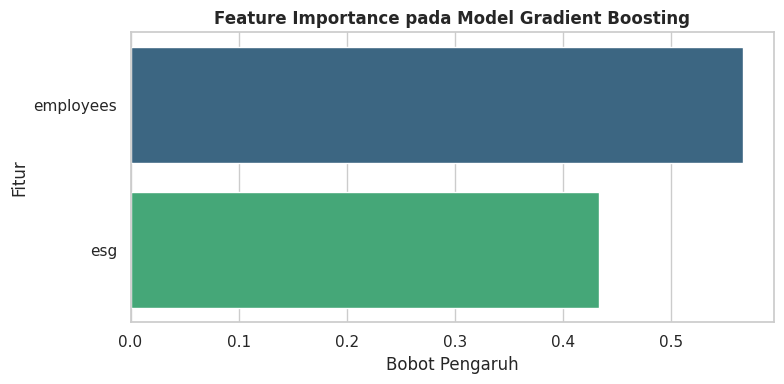

In [27]:
#Feature Importance

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

print("=== FEATURE IMPORTANCE (GRADIENT BOOSTING) ===")

# Pastikan mengambil model Gradient Boosting dari dictionary
best_model = models["Gradient Boosting"]

# Mengambil nilai pentingnya fitur
importances = best_model.feature_importances_
nama_fitur = X.columns # Ini akan mengambil 'esg' dan 'employees'

# Membuat DataFrame agar mudah ditampilkan dan diurutkan
df_importance = pd.DataFrame({
    'Fitur': nama_fitur,
    'Tingkat Kepentingan': importances
}).sort_values(by='Tingkat Kepentingan', ascending=False)

# Menampilkan angka persentase
for index, row in df_importance.iterrows():
    print(f"Fitur '{row['Fitur']}': {row['Tingkat Kepentingan']:.2%}")

# Visualisasi Bar Chart
plt.figure(figsize=(8, 4))
sns.barplot(x='Tingkat Kepentingan', y='Fitur', data=df_importance, palette='viridis', hue='Fitur', legend=False)
plt.title('Feature Importance pada Model Gradient Boosting', fontweight='bold')
plt.xlabel('Bobot Pengaruh')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

### Feature Importance / Model Interpretation

Jika model Anda mendukung interpretasi fitur, analisis fitur yang paling berpengaruh.

Contoh:
- Random Forest → `feature_importances_`
- Linear/Logistic Regression → koefisien
- Model lain → gunakan metode interpretasi yang sesuai

> **Catatan:** Feature importance tidak otomatis berarti hubungan sebab-akibat.

Jika model tidak memiliki feature importance secara langsung, Anda dapat menggunakan permutation importance atau menjelaskan keterbatasan interpretasinya.

**Analisis Feature Importance**

Berdasarkan ekstraksi Feature Importance dari model Gradient Boosting, terlihat bahwa kedua fitur memberikan kontribusi yang signifikan, namun jumlah karyawan (employees) memiliki bobot pengaruh yang sedikit lebih dominan (56.69%) dibandingkan skor esg (43.31%) dalam menentukan prediksi kebangkrutan/stabilitas finansial perusahaan.

**Interpretasi Bisnis:**

Skala Operasional (Employees):

Sebagai proksi dari ukuran perusahaan (firm size), jumlah karyawan menjadi sinyal terkuat. Ini logis karena perusahaan berskala besar (karyawan banyak) umumnya memiliki ketahanan modal, diversifikasi bisnis, dan struktur manajemen risiko yang lebih matang, sehingga lebih kuat menghindari kebangkrutan (Altman Z-Score yang aman).

Peran ESG:

Meskipun tidak mendominasi, skor ESG tetap memegang peranan yang sangat esensial (mendekati separuh bobot keputusan, yakni 43.31%). Ini membuktikan bahwa inisiatif keberlanjutan (ESG) bukanlah sekadar pencitraan perusahaan, melainkan benar-benar dipertimbangkan oleh algoritma sebagai faktor krusial yang berdampingan dengan skala operasional dalam memprediksi kesehatan finansial jangka panjang.

Kesimpulannya, model ini tidak semata-mata mengandalkan satu metrik. Algoritma memandang bahwa perusahaan yang secara finansial paling aman adalah perusahaan yang memiliki keseimbangan antara skala operasional yang memadai dan komitmen praktik ESG yang baik.


## 2.5 Memilih Model Final

Setelah membandingkan model, pilih **satu model final** untuk digunakan pada Challenge 3.

Pertimbangkan:
- Performa pada metrik utama
- Keseimbangan beberapa metrik
- Interpretabilitas
- Kompleksitas model
- Kecepatan
- Kebutuhan preprocessing
- Risiko overfitting
- Konteks penggunaan

**Model final yang saya pilih:** `Gradient Boosting`

**Alasan:**
- Keseimbangan Performa (Good Fit): Gradient Boosting menghasilkan performa terbaik secara keseluruhan dengan memimpin metrik keseimbangan F1-Score serta mencapai akurasi pengujian sebesar 71,2%.

- Tangguh Terhadap Overfitting: Model ini terbukti jauh lebih andal dalam menggeneralisasi data jika dibandingkan dengan Random Forest. Di saat Random Forest terlalu "menghafal" data latih hingga 99,9% lalu performanya anjlok ke 68,2% saat pengujian, Gradient Boosting mampu mempertahankan stabilitas prediksinya.

- Transparansi Bisnis (Interpretability): Meskipun secara komputasi lebih kompleks, algoritma boosting ini tetap menyediakan kapabilitas interpretasi fitur (feature importance). Hal ini memastikan bahwa pengaruh inisiatif keberlanjutan (skor ESG) dan skala operasional terhadap profil risiko perusahaan dapat terus dianalisis secara transparan.

- Aplikabilitas di Sektor Keuangan: Dalam konteks operasional di industri perbankan atau lembaga pembiayaan, stabilitas prediksi semacam ini sangat krusial. Kemampuan model untuk mendeteksi pola dari data yang tidak seimbang menjadikannya sistem pendukung yang rasional untuk mencegah kerugian fatal seperti salah menilai kelayakan kredit atau investasi pada entitas yang sebenarnya berisiko tinggi.

In [28]:
# Soal 2.5: Simpan model final
import joblib

# Memilih Gradient Boosting sebagai model final yang akan disimpan
model_final = models["Gradient Boosting"]

# Tentukan path penyimpanan di dalam folder Google Drive
# Agar model ini tersimpan berdampingan dengan dataset companies.csv
save_path = '/content/drive/MyDrive/Perempuan Inovasi 2026/AI Coding/Challenge/model.pkl'

# Menyimpan model ke dalam file .pkl
joblib.dump(model_final, save_path)

print(f'Model final (Gradient Boosting) berhasil disimpan secara permanen di:')
print(save_path)

Model final (Gradient Boosting) berhasil disimpan secara permanen di:
/content/drive/MyDrive/Perempuan Inovasi 2026/AI Coding/Challenge/model.pkl


**Insight Challenge 2:**

Analisis hasil eksperimen berdasarkan pertanyaan berikut (min. 5-7 kalimat):

1. **Jenis Masalah**: Apa target yang diprediksi dan mengapa masalah Anda termasuk classification atau regression?
2. **Pemilihan Model**: Model apa saja yang dibandingkan? Mengapa model tersebut dipilih?
3. **Performa Model**: Bagaimana hasil masing-masing model berdasarkan metrik yang digunakan?
4. **Kesalahan Model**: Jika classification, apa yang terlihat dari confusion matrix? Jika regression, bagaimana pola error atau nilai MAE/RMSE?
5. **Overfitting/Underfitting**: Apakah terdapat indikasi overfitting atau underfitting?
6. **Feature Importance / Interpretasi**: Fitur mana yang paling berpengaruh jika dapat dianalisis?
7. **Model Final**: Model mana yang akhirnya dipilih dan mengapa?
8. **Langkah Improvement**: Apa yang dapat dilakukan untuk meningkatkan performa model?

Jawaban:

Jenis Masalah: Target yang diprediksi adalah tingkat risiko kebangkrutan finansial perusahaan (kolom is_safe) yang diturunkan dari metrik Altman Z-Score, sehingga masalah ini secara definitif termasuk dalam binary classification karena mengelompokkan data ke dalam dua kelas diskrit, yaitu kelas 1 (Aman) dan kelas 0 (Berisiko).

Pemilihan Model: Eksperimen ini membandingkan 9 algoritma klasifikasi, mulai dari model baseline (Logistic Regression, KNN, Naive Bayes, SVM) hingga model tree-based dan ensemble tingkat lanjut (Decision Tree, Random Forest, Gradient Boosting, HistGradientBoosting, dan XGBoost). Rentang model yang luas ini dipilih secara sengaja untuk menguji apakah pola hubungan antara fitur ESG dan target bisa diselesaikan dengan algoritma linier sederhana, atau memang membutuhkan algoritma ensemble yang kompleks untuk mendeteksi pola interaksi non-linier.

Performa Model: Hasil evaluasi menunjukkan bahwa algoritma berbasis boosting memimpin, dengan Gradient Boosting mencetak F1-Score tertinggi (0.815) dan akurasi 71,2%, sementara model probabilitas sederhana seperti Naive Bayes tertinggal jauh dengan akurasi hanya 42,4%.

Kesalahan Model: Dari analisis Confusion Matrix, kelemahan utama yang paling sering muncul adalah tingginya angka False Positive (memprediksi perusahaan "Aman" padahal aslinya berisiko/hampir bangkrut). Kesalahan ini sangat terlihat pada Logistic Regression dan SVM yang mencetak 0 True Negatives dan 62 False Positives; artinya kedua model tersebut gagal total mengenali kelas berisiko dan hanya memprediksi mayoritas kelas "Aman" tanpa pertimbangan lebih lanjut.

Overfitting/Underfitting: Eksperimen membuktikan adanya tiga fenomena: Underfitting terjadi pada Naive Bayes (skor train 39,8% & test 42,4%), sementara Overfitting ekstrem terjadi pada Random Forest (menghafal data latih hingga 99,9% namun anjlok ke 68,2% di data uji). Keseimbangan terbaik (Good Fit) ditunjukkan oleh Gradient Boosting, yang mampu mengelola pola dengan skor latih 82,2% dan mempertahankan generalisasi yang baik di skor uji 71,2%.

Feature Importance / Interpretasi: Berdasarkan ekstraksi fitur pada algoritma Gradient Boosting, skala operasional perusahaan atau jumlah karyawan (employees) memiliki bobot pengaruh sebesar 56,69%, disusul oleh skor esg dengan kontribusi signifikan sebesar 43,31%. Hal ini membuktikan bahwa inisiatif keberlanjutan (ESG) bukanlah sekadar pencitraan bisnis, melainkan dipertimbangkan oleh algoritma sebagai prediktor fundamental yang berdampingan dengan ukuran perusahaan dalam menentukan kestabilan finansial.

Model Final: Gradient Gradient Boosting dipilih sebagai model final. Model ini menghasilkan keseimbangan performa (akurasi 71,2%) dan terbukti andal menghindari overfitting yang dialami oleh Random Forest. Kemampuan model ini dalam mendeteksi risiko perusahaan sangat krusial untuk diaplikasikan dalam skenario dunia nyata (seperti perbankan/pembiayaan) guna mencegah kerugian finansial akibat False Positive (salah menilai kelayakan kredit/investasi).

Langkah Improvement: Untuk meningkatkan performa model ke depannya, langkah pertama yang krusial adalah menerapkan teknik penyeimbangan data (seperti Oversampling/SMOTE) untuk mengatasi masalah ketidakseimbangan kelas (class imbalance), agar model lebih peka terhadap kelas "Tidak Aman". Selain itu, optimasi performa Gradient Boosting atau XGBoost dapat dimaksimalkan melalui Hyperparameter Tuning (misalnya menggunakan GridSearchCV pada parameter learning rate atau kedalaman pohon).

---
<a id='challenge-3'></a>
## Challenge 3 - Prediction

**Tujuan:** Menggunakan model yang telah dilatih untuk memprediksi data baru yang belum pernah dilihat.

### Instruksi
- Muat kembali model yang sudah disimpan di Challenge 2
- Buat 2-3 contoh data baru dengan fitur yang sama dengan X
- Lakukan prediksi dan tampilkan hasilnya; jika model mendukung `predict_proba`, tampilkan probability/confidence scores

In [29]:
# Soal 3.1: Muat model (jika perlu, jika di-run terpisah dari Challenge 2)
import joblib
model = joblib.load('/content/drive/MyDrive/Perempuan Inovasi 2026/AI Coding/Challenge/model.pkl')
print('✓ Model loaded')

✓ Model loaded


In [35]:
# Soal 3.2: Buat data baru untuk diprediksi
# Data harus memiliki struktur X yang sama (same columns, same order)
# Fitur yang kita pakai: 'esg' dan 'employees'
import pandas as pd

data_baru = pd.DataFrame({
    'esg': [10.5, 45.0, 25.0, 20.0],           # Contoh skor ESG dari 3 perusahaan berbeda
    'employees': [100, 150000, 15000, 5000]     # Contoh jumlah karyawan dari 3 perusahaan berbeda
})

# Tambahkan nama perusahaan untuk memudahkan kita membaca hasilnya nanti (bukan bagian dari fitur)
nama_perusahaan = ['Perusahaan A (Kecil, ESG Buruk)',
                   'Perusahaan B (Besar, ESG Bagus)',
                   'Perusahaan C (Besar, ESG Buruk)',
                   'Perusahaan D (Menengah, ESG Standar)']

print('Data baru untuk diprediksi (Fitur X):')
print(data_baru)

Data baru untuk diprediksi (Fitur X):
    esg  employees
0  10.5        100
1  45.0     150000
2  25.0      15000
3  20.0       5000


In [36]:
# Soal 3.3: Lakukan prediksi dan tampilkan hasil

hasil_prediksi = model.predict(data_baru)
print(f'Hasil Prediksi Kelas: {hasil_prediksi}')

# Tampilkan probability jika model mendukung predict_proba.
try:
    hasil_proba = model.predict_proba(data_baru)

    print('\n=== PREDICTION PROBABILITY (Tingkat Keyakinan AI) ===')
    if hasattr(model, 'classes_'):
        kelas = model.classes_
        for i, proba in enumerate(hasil_proba):
            print(f'{nama_perusahaan[i]}:')
            for label, probability in zip(kelas, proba):
                # Menambahkan terjemahan label agar mudah dipahami
                status = "Berisiko (Distress)" if label == 0 else "Aman"
                print(f'  Class {label} [{status}]: {probability:.2%}')
    else:
        print(hasil_proba)

except AttributeError:
    print('\nModel ini tidak mendukung predict_proba.')

Hasil Prediksi Kelas: [1 1 0 1]

=== PREDICTION PROBABILITY (Tingkat Keyakinan AI) ===
Perusahaan A (Kecil, ESG Buruk):
  Class 0 [Berisiko (Distress)]: 29.89%
  Class 1 [Aman]: 70.11%
Perusahaan B (Besar, ESG Bagus):
  Class 0 [Berisiko (Distress)]: 2.30%
  Class 1 [Aman]: 97.70%
Perusahaan C (Besar, ESG Buruk):
  Class 0 [Berisiko (Distress)]: 59.13%
  Class 1 [Aman]: 40.87%
Perusahaan D (Menengah, ESG Standar):
  Class 0 [Berisiko (Distress)]: 39.37%
  Class 1 [Aman]: 60.63%


---
<a id='challenge-4'></a>
## Challenge 4 - Integrasi Gemini API

**Tujuan:** Menggunakan Gemini API untuk menjelaskan hasil prediksi dengan bahasa natural yang mudah dipahami.
- Install Google AI library: `pip install google-generativeai python-dotenv`

In [41]:
# Install Google's Generative AI library
!pip install google-generativeai -q

print("✅ Instalasi selesai!")

✅ Instalasi selesai!


In [42]:
# Gunakan secrets di Google Colab untuk keamanan
from google.colab import userdata
import google.generativeai as genai

# Opsi 1: Gunakan Google Colab Secrets (RECOMMENDED)
try:
    API_KEY = userdata.get('GEMINI_API_KEY')
    print("✅ API Key loaded dari Colab Secrets")
except:
    print("⚠️  API Key tidak ditemukan di Secrets")
    print("\nPaste API key Anda di bawah:")
    API_KEY = input("GEMINI_API_KEY = ")

# Configure Gemini
genai.configure(api_key=API_KEY)
gemini_model = genai.GenerativeModel("gemini-3.8-flash")


print("✅ Gemini API configured successfully!")

✅ API Key loaded dari Colab Secrets
✅ Gemini API configured successfully!


In [44]:
# Soal 4.2: Susun prompt dan minta penjelasan dari Gemini

prompt = f"""
Anda bertindak sebagai seorang Konsultan Risiko Keuangan Eksekutif dan Pakar Keberlanjutan Bisnis (ESG) tingkat senior.
Sebuah sistem AI (Machine Learning) baru saja memproses dan memprediksi tingkat risiko stabilitas finansial untuk 4 perusahaan berdasarkan profil non-keuangan mereka.

Konteks Variabel Bisnis:
- 'esg' (Environmental, Social, and Governance): Skor dari 1-100 yang mencerminkan komitmen perusahaan terhadap keberlanjutan. Skor tinggi berarti tata kelola perusahaan sangat transparan, adaptif terhadap isu lingkungan, dan memiliki pengelolaan SDM yang baik. Skor rendah mengindikasikan kerentanan terhadap denda regulasi, masalah hukum, atau krisis reputasi jangka panjang.
- 'employees' (Jumlah Karyawan): Proksi utama untuk melihat skala perusahaan (firm size), kekuatan modal operasional, dan pangsa pasar.
- 'Target Prediksi': Angka 1 berarti "Stabilitas Keuangan Aman", sedangkan angka 0 berarti "Berisiko Bangkrut (Financial Distress)".

Data Profil Perusahaan (Input X):
{data_baru.to_string()}

Hasil Keputusan Prediksi AI (Label Prediksi):
{hasil_prediksi}

Instruksi Pembuatan Laporan Eksekutif:
Tolong susun sebuah memo analisis bisnis dalam bahasa Indonesia yang profesional namun SANGAT mudah dipahami oleh pembaca awam (seperti jajaran direksi non-IT). Dilarang keras menggunakan istilah statistik/Machine Learning yang teknis (seperti p-value, threshold, akurasi, overfitting, atau matriks).

Struktur Laporan yang Diharapkan:
1. Bedah Profil Perusahaan (Analisis Baris 0, 1, 2, dan 3):
   Jelaskan nasib dan posisi masing-masing perusahaan secara naratif. Apa makna prediksi tersebut bagi mereka secara bisnis jika kita melihat kombinasi antara ukuran skala karyawan dan skor ESG yang mereka miliki? Jangan sekadar membaca ulang angka, berikan cerita di balik angka tersebut.
2. Logika Fundamental Bisnis (Korelasi Kasat Mata):
   Jelaskan dengan argumen bisnis yang masuk akal, mengapa faktor yang seolah tidak berhubungan dengan uang (seperti "Skor ESG" dan "Jumlah Karyawan") ternyata bisa menyelamatkan atau menjerumuskan perusahaan dari kebangkrutan.
3. Rekomendasi Strategis (Mitigasi Risiko Buta):
   Berikan teguran profesional dan saran bisnis yang konkret untuk perusahaan yang saat ini dilabeli "Aman" oleh sistem, tetapi sebenarnya memiliki skor ESG yang buruk/pas-pasan. Jelaskan bom waktu (risiko tersembunyi) apa yang menanti mereka 3-5 tahun ke depan jika ESG ini diabaikan.
4. Kesimpulan Eksekutif:
   Satu paragraf penutup yang merangkum *insight* utama dari ketiga perusahaan tersebut.
"""

print("Generating explanation using Gemini API...")

try:
    gemini_response = gemini_model.generate_content(prompt)
    gemini_explanation_content = gemini_response.text
except Exception as e:
    gemini_explanation_content = f"Gemini API error: {e}"

print("\n" + "="*80)
print("AI-GENERATED EXPLANATION")
print("="*80)
print(gemini_explanation_content)
print("\nDisclosure: bagian ini dibuat dengan bantuan generative AI dan harus ditinjau manusia sebelum digunakan.")

Generating explanation using Gemini API...

AI-GENERATED EXPLANATION
**MEMORANDUM EKSEKUTIF**

* **Kepada:** Jajaran Direksi dan Dewan Komisaris
* **Dari:** Konsultan Risiko Finansial Eksekutif & Penasihat Keberlanjutan Bisnis (ESG)
* **Perihal:** Analisis Risiko Kelangsungan Usaha Berbasis Faktor Non-Finansial
* **Sifat:** Rahasia / Strategis

---

### 1. Bedah Profil Perusahaan: Cerita di Balik Keputusan Sistem

Dari hasil pemetaan kelayakan bisnis terhadap empat entitas usaha, kita melihat sebuah dinamika menarik: bagaimana kombinasi antara ukuran organisasi (jumlah karyawan) dan kualitas tata kelola (skor keberlanjutan) menentukan napas hidup sebuah entitas bisnis.

* **Perusahaan 0 (Karyawan: 100 | ESG: 10,5) – Status: AMAN**
  * **Naratif Bisnis:** Ini adalah representasi bisnis skala kecil atau *startup* tahap awal. Meskipun tata kelolanya sangat buruk (skor 10,5 mengindikasikan pengabaian hampir total terhadap aspek lingkungan, hukum, dan kesejahteraan tim), bisnis ini dinyatak

Generating explanation using Gemini API...

================================================================================
AI-GENERATED EXPLANATION
================================================================================
**MEMORANDUM EKSEKUTIF**

* **Kepada:** Jajaran Direksi dan Dewan Komisaris
* **Dari:** Konsultan Risiko Finansial Eksekutif & Penasihat Keberlanjutan Bisnis (ESG)
* **Perihal:** Analisis Risiko Kelangsungan Usaha Berbasis Faktor Non-Finansial
* **Sifat:** Rahasia / Strategis

---

### 1. Bedah Profil Perusahaan: Cerita di Balik Keputusan Sistem

Dari hasil pemetaan kelayakan bisnis terhadap empat entitas usaha, kita melihat sebuah dinamika menarik: bagaimana kombinasi antara ukuran organisasi (jumlah karyawan) dan kualitas tata kelola (skor keberlanjutan) menentukan napas hidup sebuah entitas bisnis.

* **Perusahaan 0 (Karyawan: 100 | ESG: 10,5) – Status: AMAN**
  * **Naratif Bisnis:** Ini adalah representasi bisnis skala kecil atau *startup* tahap awal. Meskipun tata kelolanya sangat buruk (skor 10,5 mengindikasikan pengabaian hampir total terhadap aspek lingkungan, hukum, dan kesejahteraan tim), bisnis ini dinyatakan **Aman**. Mengapa? Karena beban operasional mereka sangat ramping. Dengan hanya 100 karyawan, mereka memiliki kelincahan finansial untuk memangkas biaya dalam semalam jika terjadi krisis. Namun, integritas fondasi mereka sangat rapuh.
* **Perusahaan 1 (Karyawan: 150.000 | ESG: 45,0) – Status: AMAN**
  * **Naratif Bisnis:** Entitas ini adalah raksasa konglomerasi. Skor ESG 45,0 menunjukkan mereka berada di level "rata-rata pasar"—cukup patuh walau belum visioner. Bisnis ini dinyatakan **Aman** berkat fenomena *too big to fail* (terlalu besar untuk runtuh). Dengan 150.000 tenaga kerja, perusahaan ini menguasai pangsa pasar yang masif, memiliki jaringan arus kas yang terdiversifikasi, serta hubungan perbankan yang kokoh. Modal raksasa mereka mampu menjadi bantalan peredam guncangan.
* **Perusahaan 2 (Karyawan: 15.000 | ESG: 25,0) – Status: BERISIKO BANGKRUT**
  * **Naratif Bisnis:** Ini adalah korban dari sindrom "perusahaan menengah-besar yang canggung". Dengan 15.000 karyawan, beban biaya operasional dan gaji bulanan mereka sangat menggunung, namun skala mereka belum sebesar Perusahaan 1 untuk mendapatkan perlindungan modal tanpa batas. Ditambah lagi, skor ESG yang sangat rendah (25,0) menunjukkan adanya masalah disiplin internal yang parah—mungkin konflik ketenagakerjaan berulang, limbah yang bermasalah secara hukum, atau manajemen yang korup. Perusahaan ini kolaps di bawah beban operasionalnya sendiri yang diperparah oleh reputasi buruk.
* **Perusahaan 3 (Karyawan: 5.000 | ESG: 20,0) – Status: AMAN**
  * **Naratif Bisnis:** Perusahaan skala menengah ini lolos dari status krisis, tetapi posisinya berada di bibir jurang. Mereka berhasil menjaga stabilitas kas karena beban gaji 5.000 orang masih bisa ditopang oleh operasional harian mereka. Namun, skor 20,0 adalah tanda bahaya merah: ada kebocoran budaya kepatuhan yang sewaktu-waktu bisa memicu masalah hukum besar.

---

### 2. Logika Fundamental Bisnis: Mengapa Hal Non-Uang Menentukan Nasib Uang?

Banyak eksekutif terjebak dalam ilusi bahwa kebangkrutan semata-mata adalah masalah angka di neraca keuangan. Realitasnya, **faktor non-keuangan adalah pemicu arus kas masa depan**.

1. **Skor ESG adalah 'Biaya Tersembunyi' dan 'Akses Permodalan':**
   * Perusahaan dengan ESG buruk (seperti Perusahaan 2 dan 3) hidup dengan risiko sanksi hukum, denda pencemaran lingkungan, tuntutan serikat pekerja, dan biaya pergantian staf yang tinggi.
   * Saat ini, konsorsium perbankan global dan lokal mulai menolak memberi pinjaman—atau mematok bunga yang luar biasa mencekik—kepada perusahaan yang abai lingkungan dan tata kelola. Krisis likuiditas dimulai dari sini.
2. **Skala Karyawan adalah 'Pisau Bermata Dua':**
   * Karyawan adalah mesin pencetak pendapatan, tetapi juga merupakan kewajiban tetap bulanan terbesar.
   * Ketika tata kelola rusak (ESG rendah), skala yang besar tidak lagi menjadi aset, melainkan beban mematikan (seperti yang menimpa Perusahaan 2). Menghadapi boikot konsumen atau denda regulasi dengan tanggungan 15.000 keluarga di daftar gaji adalah resep kilat menuju kebangkrutan.

---

### 3. Rekomendasi Strategis: Waspada terhadap "Rasa Aman Palsu"

Bagi Perusahaan 0, 1, dan khususnya 3 yang saat ini bernapas lega dengan label "Aman", **jangan tertipu oleh status sesaat ini.** Label "Aman" dari sistem hari ini hanyalah potret kesehatan jangka pendek.

#### Bom Waktu yang Menanti 3–5 Tahun ke Depan:
* **Pengetatan Regulasi Hijau dan Pajak Karbon:** Dalam beberapa tahun ke depan, kepatuhan lingkungan bukan lagi imbauan moral, melainkan undang-undang yang mengikat. Perusahaan 0 dan 3 akan terhantam denda yang bisa menyapu bersih laba operasional mereka.
* **Krisis Boikot Pasar dan Generasi Baru:** Konsumen dan talenta terbaik generasi masa kini enggan terafiliasi dengan perusahaan perusak lingkungan atau korporasi yang menindas pekerjanya. Biaya akuisisi pelanggan akan melonjak, dan produktivitas akan anjlok drastis.
* **Penghentian Fasilitas Kredit:** Lembaga keuangan akan menutup keran pendanaan untuk sektor-sektor berisiko tinggi secara reputasi.

#### Tindakan Mitigasi Segera (Action Plan):
1. **Audit Total Kepatuhan Internal:** Khusus Perusahaan 3 dan Perusahaan 0, segera lakukan audit menyeluruh terhadap legalitas operasional, keselamatan kerja, dan transparansi laporan manajemen sebelum regulator membukanya secara paksa ke publik.
2. **Anggarkan Alokasi Transformasi Berkelanjutan:** Untuk Perusahaan 1, alihkan sebagian kas berlebih untuk menaikkan skor dari 45 ke atas 70. Sebagai korporasi raksasa, sorotan publik akan tertuju pada Anda terlebih dahulu.
3. **Ubah Paradigma Dewan Direksi:** Berhenti melihat biaya keberlanjutan sebagai "ongkos buang-buang uang". Perlakukan ini sebagai polis asuransi untuk kelangsungan hidup bisnis jangka panjang.

---

### 4. Kesimpulan Eksekutif

Skala usaha dan efisiensi biaya memang dapat membeli waktu bagi perusahaan untuk bertahan hidup hari ini, tetapi **kualitas tata kelola dan keberlanjutan (ESG) adalah satu-satunya penjamin apakah perusahaan tersebut masih memiliki hak untuk beroperasi di masa depan.** Keberuntungan Perusahaan 0, 1, dan 3 dalam mempertahankan stabilitas kas bukanlah bukti kehebatan strategi mereka, melainkan waktu pinjaman yang harus segera dibayar dengan pembenahan tata kelola sebelum bom waktu risiko meledak.

Disclosure: bagian ini dibuat dengan bantuan generative AI dan harus ditinjau manusia sebelum digunakan.


**Catatan Challenge 4:**
- Simpan/copy penjelasan dari Gemini ke dalam laporan akhir Anda sebagai bukti integrasi
- Perhatikan kualitas prompt - semakin detail prompt, semakin baik penjelasan dari Gemini
- Jika API error, pastikan API key valid dan memiliki quota yang cukup

---
<a id='challenge-5'></a>
## Challenge 5 - Responsible AI Reflection

**Tujuan:** Merefleksikan aspek etika dan tanggung jawab dalam penggunaan AI/ML.

### Instruksi
Jawab SEMUA pertanyaan reflektif berikut dalam sel markdown di bawah. Setiap jawaban minimal 3-5 kalimat, gunakan format yang rapi (bullet points, paragraf, dll).

**Jawaban Reflection (Jawab semua 5 pertanyaan):**

### 1. Bias Data
**Pertanyaan:** Apakah dataset yang digunakan berpotensi bias? Apakah data representatif untuk semua kelompok demografis (gender, usia, etnis, lokasi, dll)? Jelaskan konsekuensi jika ada bias.

**Jawaban:**
Dataset companies.csv adalah dataset yang berisi data perusahaan dan tidak memiliki data demografis sehingga bias gender, usia, etnis tidak berpengaruh secara langsung. Namun, dataset ini tetap memiliki bias yaitu dari 7.610 perusahaan, hanya sekitar 21% yang punya Altman Z-Score dan sekitar 35% yang punya skor ESG, sehingga model hanya belajar dari 989 perusahaan yang datanya lengkap. Perusahaan yang datanya lengkap kemungkinan besar adalah perusahaan besar yang transparan, sedangkan perusahaan kecil atau yang kurang terbuka jarang terwakili. Data lokasi dan sektor juga hampir kosong (hanya 68 baris), jadi kita tidak bisa memeriksa apakah model adil untuk wilayah atau sektor tertentu. Akibatnya, model bisa tampak cukup baik pada perusahaan yang mirip data training, tetapi keliru pada perusahaan yang jarang terwakili, dan keputusan seperti pemberian pinjaman bisa tidak adil bagi mereka.

---

### 2. Keterbatasan Model
**Pertanyaan:** Dalam kondisi apa model ini bisa memberikan prediksi yang salah atau menyesatkan? Apakah ada edge cases atau input yang tidak valid?

**Jawaban:**
Model saat ini hanya memakai dua fitur (x) yaitu skor ESG dan jumlah employee (karyawan), padahal dalam visualsasi scatter plot, titik-titik skor ESG terhadap Altman Z-score menyebar tanpa pola yang jelas sehingga skor ESG terlihat lemah sebagai penanda risiko kebangkrutan. Oleh karena itu, akurasi Gradient Boosting hanya 71,2%, sedikit di atas tebakan "selalu Aman" yang sudah mendapat sekitar 68,7%. Model juga masih sering salah pada perusahaan yang sebenarnya berisiko dimana 47 dari 62 perusahaan berisiko di data uji diprediksi "Aman", dan ketiga perusahaan fiktif di Challenge 3 semuanya diprediksi "Aman". Selain itu, model tetap memberi jawaban untuk input yang tidak masuk akal (misalnya skor ESG di luar rentang atau jumlah karyawan negatif) karena tidak ada pengecekan input. Label "berisiko" juga hanya berdasarkan satu batas Altman Z-Score (1,8) dan data satu waktu saja, sehingga perubahan kondisi perusahaan yang mendadak tidak tertangkap.

---

### 3. Transparansi AI Generatif
**Pertanyaan:** Penjelasan di Challenge 4 dihasilkan oleh AI (Gemini). Apakah pengguna akhir PERLU TAHU bahwa penjelasan ini dari AI? Apa risikonya jika tidak transparansi?

**Jawaban:**
Menurut saya, pengguna akhir perlu tahu bahwa penjelasan hasil analisisnya berasal dari AI karena AI bisa menulis dengan sangat meyakinkan meskipun isinya tidak sesuai dengan teori atau hasil karangan tanpa dasar atau sumber yang jelas, ditambah model Gemini yang dipakai disini hanya diberikan dua fitur dan tidak ada data kondisi perusahaan yang sebenarnya. Jika tidak transparan, pengguna bisa menganggap penjelasan itu sebagai fakta yang sudah diverifikasi lalu mengambil keputusan keuangan dari situ. Tanpa label juga sulit menentukan siapa yang bertanggung jawab ketika terjadi kesalahan. Karena itu, laporan sebaiknya diberi tulisan "dibuat oleh AI" dan peringatan bahwa hasilnya harus diperiksa manusia.

---

### 4. Dampak Sosial
**Pertanyaan:** Jika model ini digunakan dalam skala besar/nyata (misalnya di aplikasi mobile, rumah sakit, atau perusahaan), dampak apa yang mungkin timbul (positif & negatif)? Siapa saja yang bisa terpengaruh?

**Jawaban:**
Dampak positifnya, model seperti ini bisa membantu penyaringan awal risiko perusahaan dengan lebih cepat dan murah, serta membuat investor atau analis ikut memperhatikan aspek ESG. Dampak negatifnya, jika perusahaan yang sebenarnya sehat salah ditandai "berisiko", ia bisa sulit mendapat pinjaman atau investasi, dan akibatnya bisa sampai ke karyawan, pemasok, dan masyarakat di sekitarnya. Sebaliknya, perusahaan berisiko yang ditebak "Aman" bisa membuat investor atau bank rugi, dan ini justru sering terjadi pada model ini. Pihak yang bisa terpengaruh adalah bank dan investor sebagai pengguna, perusahaan yang dinilai, karyawan, serta pembuat kebijakan jika hasilnya dipakai untuk membuat keputusan.

---

### 5. Rekomendasi Responsible AI
**Pertanyaan:** Apa langkah/strategi yang bisa diambil untuk membuat sistem ini lebih bertanggung jawab (responsible AI)? Pikir tentang: transparency, fairness, accountability, security, dll.

**Jawaban:**

- **Transparansi:** beri label bahwa penjelasan dibuat oleh AI, tampilkan tingkat keyakinan prediksi (bukan hanya "Aman/Berisiko"), dan jelaskan keterbatasan model kepada pengguna.
- **Keadilan:** tambah data perusahaan kecil dan dari berbagai sektor atau wilayah, lalu periksa apakah model lebih sering salah pada kelompok tertentu.
- **Akuntabilitas:** jadikan model sebagai alat bantu, bukan pengambil keputusan akhir. Hasilnya harus ditinjau analis manusia, terutama untuk prediksi yang keyakinannya rendah.
- **Keamanan:** simpan API key di Colab Secrets (jangan ditulis langsung di kode) dan tambahkan pengecekan input supaya nilai yang tidak masuk akal ditolak.
- **Pemantauan:** evaluasi model secara berkala karena kondisi ekonomi bisa berubah-ubah, dan catat kasus ketika prediksi ternyata salah.
---

---
## Kesimpulan Akhir

**Ringkasan Pengerjaan:**
_(Tuliskan ringkasan keseluruhan, meliputi:)_
- Apa yang telah Anda pelajari dari setiap challenge?
- Kendala/challenges yang Anda hadapi dan bagaimana mengatasinya?
- Insight utama atau "aha moment" dari project ini?
- Apa yang ingin Anda pelajari lebih lanjut?

**Ringkasan Pengerjaan:**

**Yang saya pelajari dari tiap challenge:**
- Di Challenge 1, saya belajar mengenali data sebelum memodelkannya: dataset berisi 7.610 perusahaan dengan 85 kolom, tidak ada baris duplikat, tetapi banyak sekali nilai kosong. Dari histogram, skor ESG ternyata miring ke kanan, dan dari scatter plot, hubungan ESG dengan Altman Z-Score tampak lemah.
- Di Challenge 2, saya belajar membuat target `is_safe` dari Altman Z-Score (>= 1,8 dianggap aman), lalu membandingkan 9 model klasifikasi.
- Di Challenge 3, saya belajar memakai model yang sudah disimpan untuk memprediksi data baru beserta tingkat keyakinannya.
- Di Challenge 4 saya belajar menghubungkan hasil model dengan AI generatif (Gemini) agar hasilnya bisa dijelaskan dengan bahasa yang mudah dipahami. Challenge 5 mengajarkan saya bahwa model yang berjalan belum tentu aman dan adil dipakai.

**Kendala dan cara mengatasinya:**

Kendala pertama adalah data yang banyak kosong: dari 7.610 perusahaan, hanya 989 yang punya skor ESG dan Altman sekaligus, sehingga data yang dipakai untuk melatih model jauh lebih sedikit. Kendala kedua adalah memahami bahwa kolom `altman_score` tidak boleh dijadikan fitur karena target dibuat berdasarkan skor Altman tersebut, sehingga modelnya tidak benar-benar pintar menganalisis data, tapi sekadar "menyontek" hasil akhirnya saja. Kendala ketiga adalah error saat memanggil Gemini karena nama model yang lama sudah tidak tersedia, yang saya atasi dengan memasang ulang library dan memakai nama model yang masih aktif.

**Insight utama ("aha moment"):**

Ternyata, tingginya angka akurasi bisa sangat menyesatkan. Model Gradient Boosting mendapatkan akurasi 71,2% dan F1-score 0,815 yang sekilas terlihat sangat bagus. Namun, jika melihat kondisi datanya, 68,7% perusahaan di dalam dataset memang sejak awal berstatus "Aman". Artinya, model yang asal menebak semua perusahaan sebagai "Aman" pun akan otomatis mendapat nilai akurasi yang tinggi.

Masalah ini terbukti jelas saat melihat rincian tebakannya (confusion matrix). Confusion matrix menunjukkan 47 dari 62 perusahaan berisiko justru ditebak "Aman", dan Logistic Regression bahkan menebak semua perusahaan sebagai "Aman". Selain itu, Random Forest mengalami overfitting (akurasi latih 99,9% tetapi uji hanya 68,2%). Dari sini saya sadar bahwa angka yang tinggi harus dibaca bersama confusion matrix dan pembandingnya, serta bahwa ESG dan jumlah karyawan memang kurang kuat untuk memprediksi risiko kebangkrutan.

**Yang ingin saya pelajari selanjutnya:**

Saya ingin mempelajari cara menangani data yang tidak seimbang, misalnya dengan resampling atau mengatur ambang keputusan, supaya model lebih baik dalam mendeteksi perusahaan berisiko. Saya juga ingin belajar memakai fitur keuangan yang lebih banyak, melakukan tuning hyperparameter, dan menilai model dengan metrik selain akurasi seperti recall dan ROC-AUC. Terakhir, saya ingin mendalami prinsip Responsible AI, terutama soal transparansi dan pengawasan manusia saat memakai AI generatif.